In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.scale import LogScale

In [2]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR

array([0.3, 2. ])

In [3]:
# Raw = not-filtered
RR_chf_raw = np.loadtxt("data/chf206.dat")

print(f"{RR_chf_raw.min()=} {RR_chf_raw.max()=}")
print(f"{RR_chf_raw.shape=}")

RR_chf_raw.min()=0.25 RR_chf_raw.max()=20.242
RR_chf_raw.shape=(135470,)


In [4]:
# Calculate cumsum BEFORE filtering, to keep correct timings
RR_chf_t_raw = np.cumsum(RR_chf_raw)


In [5]:
# Filter out non-physiological
chf_physio_idx = (RR_chf_raw >= PHYSIO_RR[0]) & (RR_chf_raw <= PHYSIO_RR[1])
RR_chf = RR_chf_raw[chf_physio_idx]
RR_chf_t = RR_chf_t_raw[chf_physio_idx]

print(f"Filtered: {RR_chf_raw.shape[0] - RR_chf.shape[0]}")

RR_chf.shape

Filtered: 28


(135442,)

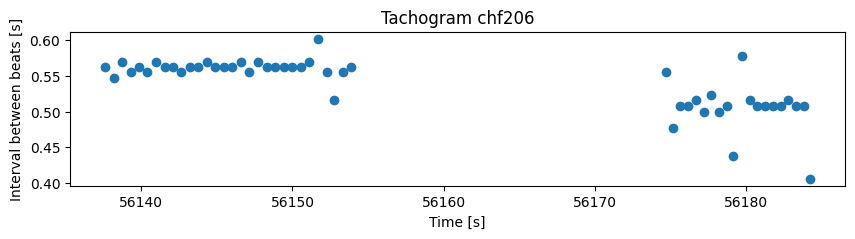

In [6]:
plt.figure(figsize=(10, 2))
fragment_s = 101957
fragment_len = 50
plt.scatter(RR_chf_t[fragment_s:fragment_s+fragment_len], RR_chf[fragment_s:fragment_s+fragment_len])
plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()

In [7]:
RR_int = np.cumsum(RR_chf - np.mean(RR_chf))

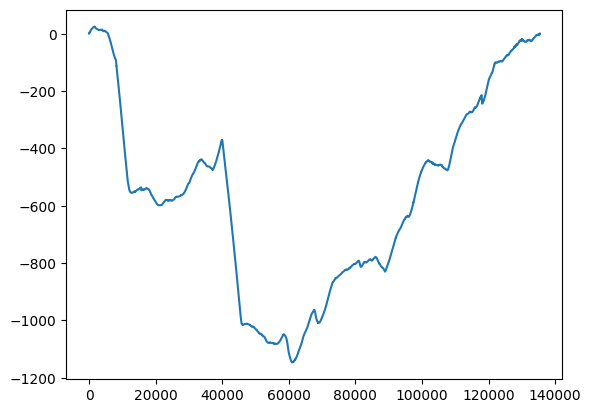

In [8]:
plt.plot(RR_int)

[-8.77197842e-03 -4.41344681e+02]
[-6.97333415e-02 -4.42023132e+02]


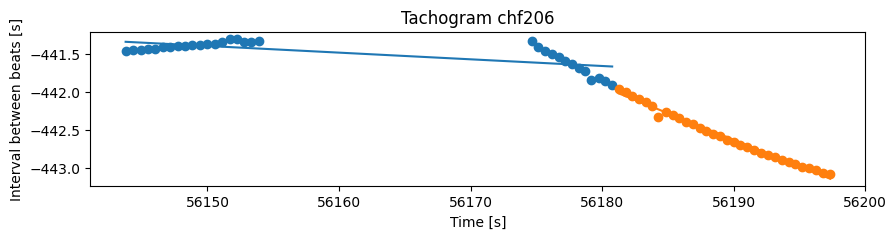

[ 1.6035937e-02 -4.4146837e+02]
[ 2.44104963e-02 -4.41406910e+02]
[-5.23895873e-03 -4.41333917e+02]
[-9.06015005e-02 -4.41601813e+02]
[-9.99295146e-02 -4.41951992e+02]
[-7.67760937e-02 -4.42311356e+02]


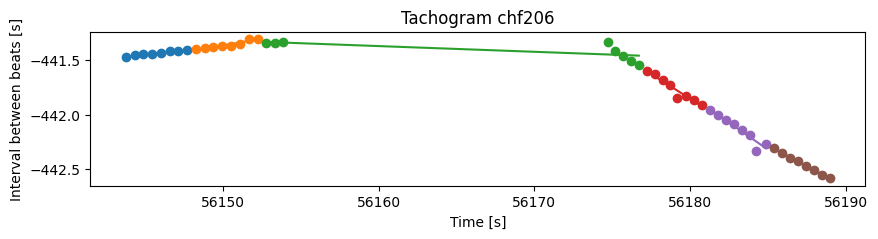

In [9]:
def plot_for_n(n):
    plt.figure(figsize=(10, 2))

    # for i in range(0, 32, n):
    i1 = 101968
    for i in range(i1, i1 + 48, n):
        x_offset = RR_chf_t[i]
        x, y = RR_chf_t[i:i + n] - x_offset, RR_int[i:i + n]
        b = np.polyfit(x, y, 1)
        print(b)
        plt.scatter(x + x_offset, y)

        lx = x[[0,-1]]
        ly = b[0]*lx + b[1]
        plt.plot(lx + x_offset, ly)


    plt.xlabel("Time [s]")
    plt.ylabel("Interval between beats [s]")
    plt.title("Tachogram chf206")
    plt.show()

plot_for_n(32)
plot_for_n(8)

In [10]:
def F(n):
    N = int(np.floor(len(RR_chf) / n) * n)

    # Each row is one window of length n
    x = RR_chf_t[:N].reshape(-1, n)
    y = RR_int[:N].reshape(-1, n)

    # Centering x and y in each window (this also serves as the offset)
    x = x - x.mean(axis=1, keepdims=True)
    y = y - y.mean(axis=1, keepdims=True)

    # Least squares line for all windows at once:
    # slope = sum(x*y) / sum(x^2), intercept = 0 after centering
    slope = np.sum(x * y, axis=1, keepdims=True) / np.sum(x**2, axis=1, keepdims=True)
    ly = slope * x

    err = np.mean((y - ly)**2)
    F_n = np.sqrt(err)
    return F_n

In [11]:
F(64)

0.0806221319083661

In [12]:
ns = np.arange(4, 65)
F_total = np.array([F(n) for n in ns])

Text(0, 0.5, '$log_{10}F(n)$')

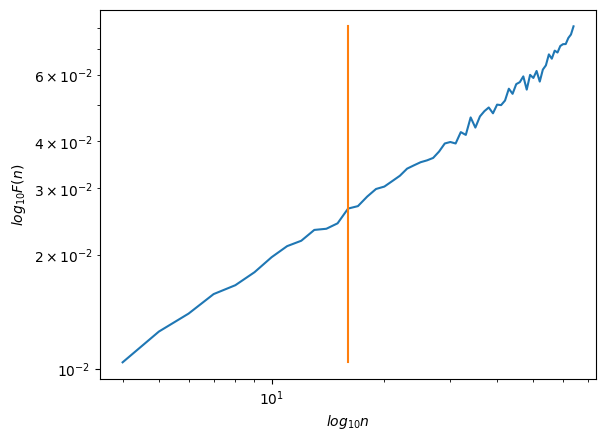

In [13]:
plt.plot(ns, F_total)
plt.loglog()
plt.plot([16, 16], [F_total.min(), F_total.max()])
plt.xlabel("$log_{10}n$")
plt.ylabel("$log_{10}F(n)$")

In [14]:
def calc_alpha(alpha_n, alpha_F):
    alpha_n = np.log(alpha_n)
    alpha_F = np.log(alpha_F)
    alpha = np.polyfit(alpha_n, alpha_F, 1)[0]
    return alpha

0.6459462380008122

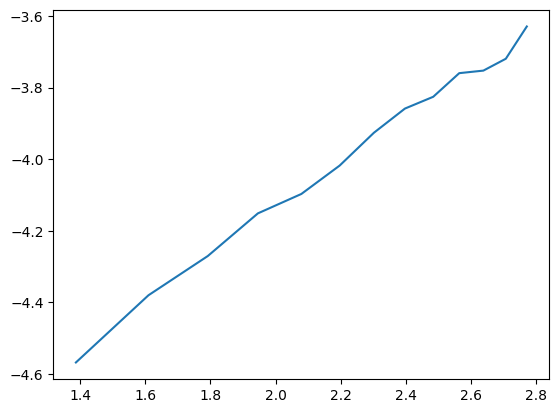

In [15]:
alpha1_n = ns[ns <= 16]
alpha1_n = np.log(alpha1_n)

alpha1_F = F_total[ns <= 16]
alpha1_F = np.log(alpha1_F)
plt.plot(alpha1_n, alpha1_F)

alpha1 = np.polyfit(alpha1_n, alpha1_F, 1)[0]
alpha1

In [16]:
alpha1 = calc_alpha(ns[ns<=16], F_total[ns<=16])
alpha2 = calc_alpha(ns[ns>16], F_total[ns>16])
# (0.6459462380007214, 0.7847639933071208)
alpha1, alpha2

(0.6459462380008122, 0.7847639933071232)

In [17]:
from DFA import dfa

def dfa_for_nsr(dat: str):
    RR_chf_raw = np.loadtxt(f"data/{dat}.dat")
    _, alpha1, alpha2, log_ns, log_F_total = dfa(RR_chf_raw)
    print(f"{dat}: {alpha1=:.4f} {alpha2=:.4f}")

    plt.plot(log_ns, log_F_total)
    threshold_x = log_ns[12]
    plt.plot([threshold_x, threshold_x], [log_F_total.min(), log_F_total.max()])
    plt.xlabel("$log_{10}n$")
    plt.ylabel("$log_{10}F(n)$")
    plt.title(dat)
    plt.show()


chf206: alpha1=0.6459 alpha2=0.7848


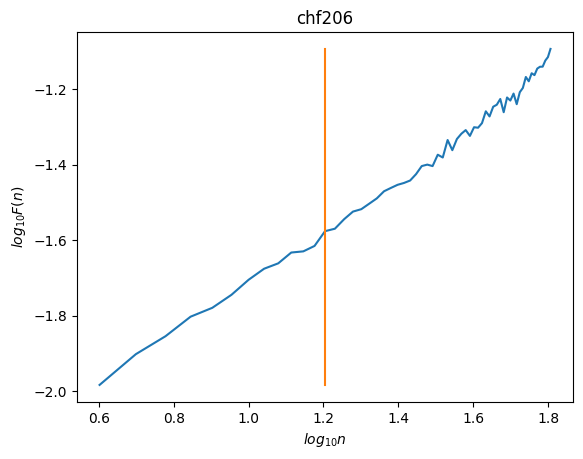

In [18]:
dfa_for_nsr("chf206")

nsr001: alpha1=1.1758 alpha2=1.1395


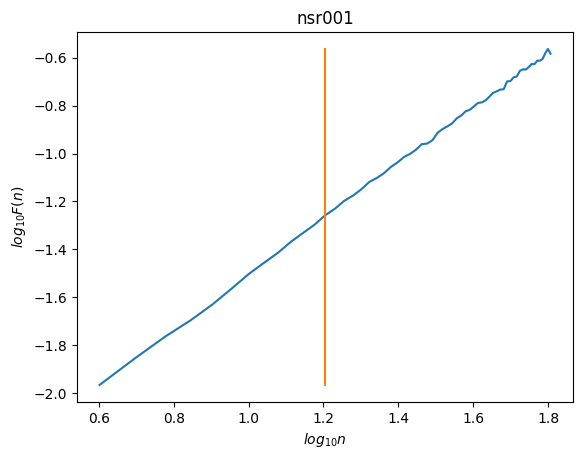

In [19]:
dfa_for_nsr("nsr001")